# ISM 6564 — Week 4 lecture notebook: models that read in order

Week 3 ended on a wall. A bag of words turns *"the repair was not good and the
refund was fast"* and *"the repair was good and the refund was not fast"* into
the **same row of numbers** — so no model downstream can tell them apart. It
also cost us real accuracy: many of the tickets our router got wrong ask for
two things, and the dispatchers route them by whichever request comes
**first**. A bag of words has no idea what came first.

This week fixes that in four steps, each one small:

| § | Idea | One-line version |
|---|---|---|
| 2 | **Word vectors** | give every *word* a list of numbers that captures its meaning |
| 3 | **Reading in order (RNN)** | read the words one at a time, keeping a running memory |
| 4 | **Remembering further (LSTM)** | give that memory gates, so it does not fade on long text |
| 5 | **The router, rebuilt** | same tickets, same training loop as Week 3 — only the model changes |
| 6 | **The same model, writing** | train the LSTM to predict the *next word* — a language model in miniature |
| 7 | **Choosing words** | how a model that predicts the next word turns probabilities into text |

Everything runs on an ordinary laptop CPU in a minute or two, and every file
loads from the course data repository, so this notebook runs anywhere.

---
## 0 — Setup

In [1]:
import io
import random
import time
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Where every data file lives. Nothing loads from your own disk.
DATA = "https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/"

print(f"torch {torch.__version__} — these models are small, so the CPU is all we need")

torch 2.13.0+cpu — these models are small, so the CPU is all we need


---
## 1 — Where Week 3 left us

The bag-of-words ceiling, one more time. Two sentences with opposite meanings,
counted word by word:

In [2]:
from sklearn.feature_extraction.text import CountVectorizer

docs = ["the repair was not good and the refund was fast",
        "the repair was good and the refund was not fast"]

counts = CountVectorizer().fit_transform(docs).toarray()
print(counts)
print("identical rows?", bool((counts[0] == counts[1]).all()))

[[1 1 1 1 1 1 2 2]
 [1 1 1 1 1 1 2 2]]
identical rows? True


Same words, same counts, one vector. The information about **which word came
before which** was thrown away the moment we counted. Everything in this
notebook is about keeping it.

---
## 2 — Words as vectors

In a bag of words, *refund* and *payment* are two unrelated columns — the
model has to learn from scratch that they are related.
**Word vectors** fix that by describing every word with a short list of
numbers, arranged so that words used in similar ways get similar numbers.

The idea behind them fits in one sentence: **a word is the company it keeps.**
*Refund* and *payment* keep similar company (*processed, account, card,
days*), so they end up close together.

**Where the numbers come from.** GloVe (*Global Vectors*; Pennington, Socher
and Manning, Stanford, 2014) is built in two steps. First, count how often
every pair of words appears near each other across 6 billion words of
Wikipedia and news text. Second, compress each word's long, mostly-zero row of
counts into 100 dense numbers, the same move Week 3 made when `TruncatedSVD`
squeezed TF-IDF rows into dense columns. Words that keep the same company end
up with similar numbers.

GloVe belongs to a family called **word embeddings**. It sits between LSA
(1990: counts and SVD, which you used in Weeks 2 and 3) and word2vec (Google,
2013: a tiny neural network that predicts each word's neighbours), and it came
before fastText (2016: vectors built from word pieces). Three things the family
shares: it is *self-supervised* (no labels; the text is the teacher),
*pretrained* (trained once on huge text, downloaded by everyone), and *static*
(one vector per word, whatever the sentence; Week 5 removes that limit).

The full release is 400,000 words × 100 numbers; we load its 15,095 most common
words. The companion notebook `ism6564-week04-word-vector-math.ipynb` works
through every calculation in this section step by step, including the
count-then-compress recipe run on our own tickets.

In [3]:
# np.load cannot read a web address directly, so we download the bytes first.
url = DATA + "week-02-vectors-similarity/data/glove_6b_100d_subset.npz"
blob = np.load(io.BytesIO(urllib.request.urlopen(url).read()), allow_pickle=True)

words = [str(w) for w in blob["words"]]
vectors = blob["vectors"]                         # one row of 100 numbers per word
index = {w: i for i, w in enumerate(words)}

print(f"{len(words):,} words, each described by {vectors.shape[1]} numbers")
print("\n'refund' is:", vectors[index["refund"]][:8].round(2), "... (92 more)")

15,095 words, each described by 100 numbers

'refund' is: [ 0.27 -0.21  0.48 -0.53 -0.29  0.27 -0.2   0.82] ... (92 more)


The numbers mean nothing on their own. What matters is **which words are
near each other**, and we measure "near" with Week 2's cosine similarity.

In [4]:
# Normalise every vector to length 1, so a dot product IS the cosine similarity.
unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

def most_similar(vec, n=5, exclude=()):
    """The n words whose vectors point most nearly the same way as vec."""
    vec = vec / np.linalg.norm(vec)
    sims = unit @ vec                             # cosine with every word at once
    best = [i for i in np.argsort(-sims) if words[i] not in exclude][:n]
    return [(words[i], round(float(sims[i]), 3)) for i in best]

def cosine(a, b):
    return float(unit[index[a]] @ unit[index[b]])

print(f"refund vs payment: {cosine('refund', 'payment'):.3f}   (related)")
print(f"refund vs tent   : {cosine('refund', 'tent'):.3f}   (unrelated)\n")

for w in ["refund", "tent", "excellent"]:
    print(f"{w:>10} ->", most_similar(vectors[index[w]], exclude={w}))

refund vs payment: 0.711   (related)
refund vs tent   : 0.009   (unrelated)

    refund -> [('refunds', 0.848), ('payment', 0.711), ('refunded', 0.673), ('fees', 0.641), ('checks', 0.637)]
      tent -> [('tents', 0.763), ('makeshift', 0.668), ('picnic', 0.627), ('shelter', 0.618), ('hut', 0.611)]
 excellent -> [('good', 0.794), ('quality', 0.761), ('terrific', 0.742), ('superb', 0.74), ('best', 0.729)]


**Picture it.** 100 numbers per word cannot be drawn, but Week 2's trick —
squashing many columns down to two (here with PCA, a close cousin of SVD) —
gives a faithful-enough sketch. Sixteen words, four kinds:

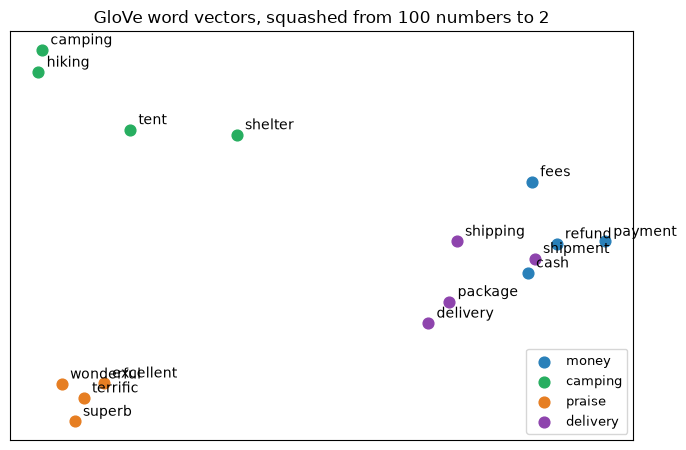

In [5]:
from sklearn.decomposition import PCA

groups = {"money": ["refund", "payment", "fees", "cash"],
          "camping": ["tent", "shelter", "camping", "hiking"],
          "praise": ["excellent", "terrific", "superb", "wonderful"],
          "delivery": ["delivery", "shipping", "shipment", "package"]}
picked = [w for ws in groups.values() for w in ws]
xy = PCA(n_components=2, random_state=SEED).fit_transform(vectors[[index[w] for w in picked]])

fig, ax = plt.subplots(figsize=(7, 4.6))
for (name, ws), colour in zip(groups.items(), ["#2980b9", "#27ae60", "#e67e22", "#8e44ad"]):
    pts = xy[[picked.index(w) for w in ws]]
    ax.scatter(pts[:, 0], pts[:, 1], s=60, color=colour, label=name)
    for w, (px, py) in zip(ws, pts):
        ax.annotate(w, (px, py), textcoords="offset points", xytext=(6, 4), fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("GloVe word vectors, squashed from 100 numbers to 2")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

Nobody told GloVe that *refund* belongs with *payment* and *fees*, or that
*excellent* belongs with *terrific* and *superb*. It worked that out from the
company the words keep. Because meaning is now **geometry**, you can
even do arithmetic with it — the famous analogy test:

In [6]:
def analogy(a, b, c):
    """a is to b as c is to ... ?   computed as  b - a + c"""
    target = vectors[index[b]] - vectors[index[a]] + vectors[index[c]]
    return most_similar(target, n=3, exclude={a, b, c})

print("man    : king   ::  woman : ?", analogy("man", "king", "woman"))
print("france : paris  ::  japan : ?", analogy("france", "paris", "japan"))

man    : king   ::  woman : ? [('queen', 0.783), ('monarch', 0.693), ('throne', 0.683)]
france : paris  ::  japan : ? [('tokyo', 0.892), ('osaka', 0.742), ('japanese', 0.709)]


**The caveat, measured.** Word vectors learn the company words keep — including
the stereotypes in the text they were trained on. Ask the same arithmetic about
jobs:

In [7]:
print("man : doctor   ::  woman : ?", analogy("man", "doctor", "woman"))
print("man : engineer ::  woman : ?", analogy("man", "engineer", "woman"))

man : doctor   ::  woman : ? [('nurse', 0.776), ('physician', 0.713), ('doctors', 0.679)]
man : engineer ::  woman : ? [('technician', 0.659), ('educator', 0.615), ('surgeon', 0.596)]


Nothing in the method is biased; the *text* was, and the vectors faithfully
learned it. Any system built on these vectors — a résumé screener, a support
router — inherits that unless someone checks. Week 10 comes back to this.

### Word vectors still lose the order

Word vectors improve what each word *means*. They do nothing about order. The
simplest way to turn a sentence into one vector — average its word vectors —
throws the order away all over again:

In [8]:
def average_vector(sentence):
    return np.mean([vectors[index[w]] for w in sentence.split()], axis=0)

a = average_vector(docs[0])
b = average_vector(docs[1])
print("identical sentence vectors?", bool(np.allclose(a, b)))

identical sentence vectors? True


Same problem as §1, just with better numbers. To keep order we need a model
that **reads** the words in sequence. First, one piece of machinery: how a
PyTorch model stores word vectors.

### `nn.Embedding` — a lookup table of word vectors

**An ID is not an embedding.** Turning a word into numbers takes two lookups:

1. **The vocabulary: word → ID.** An agreed list that gives every word a
   number, like a row number in a spreadsheet. The numbers mean nothing: in our
   GloVe file *refund* is row 15,002 and *payment* row 4,132, and the rows next
   to *refund* are *teller* and *warranty*. You cannot do maths on IDs, and a
   different vocabulary gives different IDs.
2. **The embedding table: ID → vector.** Each ID points at a row of learned
   numbers. That row *is* the word's embedding, and it is where the meaning
   lives: related words get similar rows.

Think of a customer ID and a customer profile: the ID says *which* customer,
the profile says *what they are like*, except that nobody designed the
embedding's columns; they were learned.

`nn.Embedding` is the second lookup: a table with one row per ID. Hand it a
tensor of IDs and it returns their rows. The rows are **learned numbers**,
exactly like the `nn.Linear` weights you counted in Week 3 — training adjusts
them, while the vocabulary stays fixed. (Or you can fill the table with GloVe's
rows to start: `nn.Embedding.from_pretrained`.)

In [9]:
torch.manual_seed(SEED)

# two reserved IDs first, then one per word - the same convention the router uses in §5
tiny_vocab = {"<pad>": 0, "<unk>": 1, "the": 2, "tent": 3, "arrived": 4, "damaged": 5}
word_table = nn.Embedding(num_embeddings=len(tiny_vocab), embedding_dim=3, padding_idx=0)

print("the table: one row per ID, 3 numbers per row - random until trained")
for word, i in tiny_vocab.items():
    print(f"   {i}  {word:<9} {word_table.weight[i].detach().numpy().round(3)}")

tokens = ["the", "tent", "was", "damaged"]      # "was" is not in the vocabulary
ids = torch.tensor([tiny_vocab.get(t, tiny_vocab["<unk>"]) for t in tokens])

print("\ntokens:", tokens)
print("IDs   :", ids.tolist(), "  <- 'was' became 1, the <unk> row")
print("rows  :")
print(word_table(ids).detach().numpy().round(3))   # 4 IDs in -> 4 rows
print("\nlooking up is just selecting rows:",
      bool(torch.equal(word_table(ids), word_table.weight[ids])))

the table: one row per ID, 3 numbers per row - random until trained
   0  <pad>     [0. 0. 0.]
   1  <unk>     [ 0.44  -0.758  1.078]
   2  the       [0.801 1.681 0.356]
   3  tent      [-0.687  0.61   1.335]
   4  arrived   [-0.232  0.042 -0.252]
   5  damaged   [ 0.86  -0.31  -0.396]

tokens: ['the', 'tent', 'was', 'damaged']
IDs   : [2, 3, 1, 5]   <- 'was' became 1, the <unk> row
rows  :
[[ 0.801  1.681  0.356]
 [-0.687  0.61   1.335]
 [ 0.44  -0.758  1.078]
 [ 0.86  -0.31  -0.396]]

looking up is just selecting rows: True


Three things to take from that output.

**The rows start as random numbers.** `embedding_dim=3` gives every ID three
trainable numbers, and nothing more: the three positions have no meaning yet,
and none was designed. **Meaning is learned from the task.** Training measures
how much each row contributed to the model's error and nudges the rows it used,
so words that play similar roles drift towards similar numbers. **The
word-to-ID mapping stays fixed:** *tent* is ID 3 and reads row 3 from the first
batch to the last. The ID never changes; the numbers in row 3 do.

In one sentence: `nn.Embedding` starts as a randomly filled lookup table, and
training turns its rows into useful representations by adjusting them to reduce
the model's loss.

Two reserved IDs earn their places: `<pad>` (0) fills short texts so a batch is
a rectangle, and `padding_idx=0` keeps that row zero; `<unk>` (1) catches any
word the vocabulary has never seen, like *was* above. Real models use 50–300
numbers per word instead of 3.

---
## 3 — Reading in order: the recurrent neural network (RNN)

An RNN reads a sentence **one word at a time** and keeps a running **memory**
(called the *hidden state*) — a short list of numbers summarising everything
read so far. At every step it combines two things: its memory so far, and the
next word. The final memory is the model's summary of the whole sentence.

That one change fixes the order problem. Take the two repair sentences from §1:
same words, so the same counts (§1) and the same averaged word vector (§2).
An RNN reads them in different sequences, so its memory ends in a different
place. Watch it on an untrained RNN with a memory of just 4 numbers.

Two sizes are being chosen in the next cell, and they are separate choices:
`nn.Embedding(..., 4)` sets how many numbers describe each **word**;
`nn.RNN(input_size=4, hidden_size=4)` sets how many numbers the **memory**
carries from word to word. They happen to be equal here to keep the demo
small. The router in §5 uses 64 and 64; a model fed GloVe vectors would use
100 in and whatever memory size you chose — the RNN's weights include a
64 × 100 table that adapts one width to the other.

In [10]:
torch.manual_seed(SEED)

# A tiny vocabulary: just the words of the two repair sentences from §1.
vocab3 = {"<pad>": 0}
for w in " ".join(docs).split():
    vocab3.setdefault(w, len(vocab3))

embed = nn.Embedding(len(vocab3), 4, padding_idx=0)          # each word -> 4 numbers
rnn = nn.RNN(input_size=4, hidden_size=4, batch_first=True)   # a memory of 4 numbers

def read(sentence):
    ids = torch.tensor([[vocab3[w] for w in sentence.split()]])
    outputs, final_memory = rnn(embed(ids))
    return outputs[0], final_memory[0, 0]

steps_1, final_1 = read(docs[0])
steps_2, final_2 = read(docs[1])

def show(memory):                                   # 4 numbers, 2 decimals, signs lined up
    return "[" + "  ".join(f"{v:+.2f}" for v in memory.tolist()) + "]"

print("the memory after each word, both sentences side by side\n")
print("     sentence 1                         sentence 2")
for i, (w1, h1, w2, h2) in enumerate(zip(docs[0].split(), steps_1, docs[1].split(), steps_2), 1):
    same = "same" if torch.allclose(h1, h2) else "different"
    print(f"{i:>2}  {w1:>6} {show(h1)}   {w2:>6} {show(h2)}   {same}")

print("\nmemory after the last word:")
print("   sentence 1 (repair not good):", show(final_1))
print("   sentence 2 (refund not fast):", show(final_2))
print("identical?", bool(torch.allclose(final_1, final_2)))

the memory after each word, both sentences side by side

     sentence 1                         sentence 2
 1     the [-0.78  +0.61  +0.80  +0.17]      the [-0.78  +0.61  +0.80  +0.17]   same
 2  repair [+0.80  -0.69  +0.53  -0.36]   repair [+0.80  -0.69  +0.53  -0.36]   same
 3     was [+0.28  -0.10  -0.15  -0.70]      was [+0.28  -0.10  -0.15  -0.70]   same
 4     not [-0.70  +0.44  -0.09  -0.48]     good [-0.54  +0.77  +0.28  -0.01]   different
 5    good [-0.38  +0.19  +0.68  +0.04]      and [+0.27  +0.23  +0.78  +0.30]   different
 6     and [+0.53  +0.32  +0.75  +0.51]      the [-0.67  +0.23  +0.87  +0.17]   different
 7     the [-0.71  +0.25  +0.87  +0.02]   refund [+0.93  -0.89  +0.02  -0.77]   different
 8  refund [+0.93  -0.88  -0.02  -0.75]      was [+0.01  +0.43  -0.46  -0.71]   different
 9     was [-0.00  +0.44  -0.46  -0.72]      not [-0.79  +0.27  +0.05  -0.61]   different
10    fast [+0.75  -0.58  -0.56  -0.92]     fast [+0.91  -0.85  -0.26  -0.84]   different

memory

Both sentences start *the repair was*, so for three words the memory is
exactly the same. At word 4 one reads *not* and the other reads *good*, and
from there the memories part ways — ending somewhere different, which neither
word counts nor averaged word vectors could do. This RNN is untrained, so its
numbers mean nothing *yet*; training (§5) is what teaches the memory to hold
*useful* information, such as "a *not* just went by".

**What training does here** is exactly what it did in Week 3. *Predict:* the
final memory is turned into one score per label. *Measure:* the loss
(cross-entropy) compares those scores with the true label and gives one
number for how wrong. *Nudge:* backpropagation adjusts every learned number
to shrink that number — the RNN's weights, the embedding rows, and the head.
Repeated over thousands of texts, that is what teaches the memory which things
are worth holding on to.

### The catch: the memory keeps only the latest words

An RNN rewrites its entire memory at every word, so the memory at the end is
dominated by the words it read **last**. Everything earlier has been mixed and
squashed again at every step since.

We can measure it. Read a 40-word text, then ask of each word: if this word
changed a little, how much would the final memory move?

In [11]:
torch.manual_seed(SEED)

long_text = torch.randint(1, len(vocab3), (1, 40))     # a 40-word text
word_vectors = embed(long_text)
word_vectors.retain_grad()

outputs, final_memory = rnn(word_vectors)
final_memory.norm().backward()              # how much does each word still move it?

influence = word_vectors.grad[0].norm(dim=1)
influence = (influence / influence.max()).detach()      # 1.0 = the biggest effect

print("how much each word still moves the memory after all 40 words:")
for start in range(0, 40, 8):
    row = "  ".join(f"{v:.3f}" for v in influence[start:start + 8])
    print(f"   words {start + 1:>2}-{start + 8:>2}:  {row}")

print(f"\nthe last word : {influence[-1]:.3f}")
print(f"8 words back  : {influence[-9]:.3f}")
print(f"the first word: {influence[0]:.1e}   <- nothing left")

how much each word still moves the memory after all 40 words:
   words  1- 8:  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
   words  9-16:  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
   words 17-24:  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
   words 25-32:  0.000  0.000  0.000  0.000  0.000  0.000  0.001  0.002
   words 33-40:  0.004  0.008  0.056  0.109  0.189  0.366  1.000  0.968

the last word : 0.968
8 words back  : 0.002
the first word: 1.4e-18   <- nothing left


Read the numbers from the right: the last handful of words carry almost all of
it, and by about ten words back there is little left. The first word's effect
is around 10⁻¹⁸ of the last word's — zero for any practical purpose.

That has two consequences, and both hurt:

- **The prediction cannot depend on early words.** Whatever the model read
  first has been squashed out of the memory by the end.
- **It cannot even learn to keep them.** Training works backwards through the
  same chain, so the signal that would teach the model "hold on to the first
  request" shrinks just as fast. This is the *vanishing gradient* problem.

These numbers come from an untrained RNN, where the decay is at its starkest;
training changes the numbers but not the shape. And it is exactly where our
router's hardest tickets live: the label follows the **first** request, and a
ticket can run for 70 more words after it.

In [12]:
# SO it uses backprop to learn the words, and uses gradient descent to tweak, though it is skewed towards the lastest words(aka the first words after backprop)

---
## 4 — Remembering further: LSTM and GRU

The **LSTM** (*long short-term memory*) keeps the RNN's word-by-word reading
but protects the memory with three **gates** — learned switches that decide,
at every word:

- **forget gate** — how much of the old memory to keep,
- **input gate** — how much of the new word to write in,
- **output gate** — how much of the memory to use right now.

Because the model can choose to *keep* something unchanged for many words, the
first request of a long ticket can survive to the end.

The **GRU** (*gated recurrent unit*, 2014) is a simplification: one memory
instead of two, and two gates instead of three. An **update gate** decides
whether to keep the old memory or take a new draft, which does the jobs of the
LSTM's forget and input gates with a single dial. A **reset gate** decides how
much of the old memory to use when writing that draft. Why learn both? The
LSTM (1997) was the workhorse of 2010s language technology, but when researchers
compared the two head to head, neither won consistently. The GRU has fewer
learned numbers, so the practical habit is to try the lighter one and keep it
if accuracy ties. Assignment 4 asks you to do exactly that.

The gates are not free. Each is its own set of weights, so the layers get
bigger:

In [13]:
def count(module):
    return sum(p.numel() for p in module.parameters())

for name, layer in [("RNN ", nn.RNN(64, 64)), ("GRU ", nn.GRU(64, 64)), ("LSTM", nn.LSTM(64, 64))]:
    print(f"{name} with 64 inputs and a 64-number memory: {count(layer):,} learned numbers")

RNN  with 64 inputs and a 64-number memory: 8,320 learned numbers
GRU  with 64 inputs and a 64-number memory: 24,960 learned numbers
LSTM with 64 inputs and a 64-number memory: 33,280 learned numbers


In PyTorch, swapping one for another is literally one word: `nn.RNN`,
`nn.GRU`, or `nn.LSTM`. So let us put them to work.

---
## 5 — The router, rebuilt: same tickets, same loop, new model

Week 3 promised that this week would keep the training loop and change only
the model. Here it is. Same Northwind tickets, same duplicate removal, same
60/20/20 splits, same seed — so every number is directly comparable to last
week's.

In [14]:
from sklearn.model_selection import train_test_split

tickets = pd.read_csv(DATA + "week-03-text-classification/data/tickets.csv").fillna("")
tickets["text"] = (tickets["subject"] + " " + tickets["body"]).str.strip()
tickets = tickets.drop_duplicates("body").reset_index(drop=True)

train_df, temp_df = train_test_split(tickets, test_size=0.40, stratify=tickets["queue"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["queue"], random_state=SEED)

QUEUES = sorted(tickets["queue"].unique())
print(f"train {len(train_df)}   val {len(val_df)}   test {len(test_df)}   queues: {QUEUES}")

train 1758   val 586   test 586   queues: ['account-access', 'billing', 'product-question', 'returns-warranty', 'shipping']


**The number to beat** — Week 3's baseline, TF-IDF + logistic regression,
refit here on the identical split:

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.perf_counter()
tfidf = TfidfVectorizer(min_df=3)
logreg = LogisticRegression(max_iter=1000).fit(tfidf.fit_transform(train_df["text"]), train_df["queue"])
baseline_secs = time.perf_counter() - t0

baseline_pred = logreg.predict(tfidf.transform(test_df["text"]))
baseline_acc = (baseline_pred == test_df["queue"].values).mean()
print(f"bag of words (Week 3):  test accuracy {baseline_acc:.4f}   fit in {baseline_secs:.2f} s")

bag of words (Week 3):  test accuracy 0.8857   fit in 0.12 s


### Step 1 — turn each ticket into a row of word IDs

A reading model needs the words **in order**, not counted. Three small steps:

1. **Split into words** — with the *same* tokenizer TF-IDF used last week, so
   both models see identical words.
2. **Give every word an ID number**, using the **training tickets only** (the
   Week 3 rule: anything learned from data is learned from train). Words seen
   fewer than twice, or never, become `<unk>` ("unknown", ID 1).
3. **Make every ticket the same length.** A batch has to be a rectangle, so
   shorter tickets get `<pad>` (ID 0) added **in front**. Padding at the front
   means the real words always come last — so the model's final memory is
   always taken right after the last real word.

In [16]:
tokenize = CountVectorizer().build_analyzer()     # Week 3's tokenizer: lowercase, 2+ letter words
MAX_LEN = 80                                      # the longest ticket has 72 words

word_counts = Counter(w for text in train_df["text"] for w in tokenize(text))
vocab = {"<pad>": 0, "<unk>": 1}
for w, n in word_counts.items():
    if n >= 2:
        vocab[w] = len(vocab)

def encode(texts):
    rows = np.zeros((len(texts), MAX_LEN), dtype=np.int64)       # start with all <pad>
    for i, text in enumerate(texts):
        ids = [vocab.get(w, 1) for w in tokenize(text)][:MAX_LEN]
        rows[i, MAX_LEN - len(ids):] = ids                         # real words at the END
    return torch.from_numpy(rows)

queue_id = {q: i for i, q in enumerate(QUEUES)}
X_train, X_val, X_test = encode(train_df["text"]), encode(val_df["text"]), encode(test_df["text"])
y_train = torch.tensor([queue_id[q] for q in train_df["queue"]])
y_val   = torch.tensor([queue_id[q] for q in val_df["queue"]])
y_test  = np.array([queue_id[q] for q in test_df["queue"]])

print(f"vocabulary: {len(vocab)} words (from training tickets only)")
print("\na ticket:", test_df["text"].iloc[0][:90], "...")
print("as IDs  :", X_test[0].tolist()[-16:], "(last 16 of 80 shown)")

vocabulary: 752 words (from training tickets only)

a ticket: Support request My order history disappeared after I merged my old account with my new ema ...
as IDs  : [445, 335, 446, 35, 94, 89, 171, 35, 447, 87, 135, 171, 5, 136, 137, 1] (last 16 of 80 shown)


### Step 2 — the model: embedding → reader → one score per queue

Three layers, read top to bottom like a recipe. `cell` is the only thing we
will change between experiments — `nn.RNN` or `nn.LSTM`.

In [17]:
class TicketReader(nn.Module):
    def __init__(self, cell, vocab_size, n_queues=5):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, 64, padding_idx=0)   # word ID -> 64 numbers
        self.reader = cell(64, 64, batch_first=True)               # reads word by word, 64-number memory
        self.head = nn.Linear(64, n_queues)                        # final memory -> 5 queue scores

    def forward(self, ids):
        word_vectors = self.embed(ids)                  # (tickets, 80 words, 64 numbers)
        outputs, final = self.reader(word_vectors)      # read all 80 positions in order
        if isinstance(final, tuple):                    # an LSTM also returns its protected cell memory
            final = final[0]                            # ...we want the hidden state, as for the RNN
        return self.head(final[-1])                     # the memory after the LAST word

### Step 3 — train with Week 3's loop

This is the v4 loop from the PyTorch step-by-step notebook, unchanged: the five
lines, a validation check after every epoch, early stopping with patience, and
a roll-back to the best weights.

In [18]:
from torch.utils.data import TensorDataset, DataLoader

def train_reader(cell, seed=SEED, max_epochs=40, patience=6):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model = TicketReader(cell, len(vocab))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    batches = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

    best_val, best_weights, waited = 0.0, None, 0
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in batches:
            optimizer.zero_grad()                 # 1. clear old gradients
            loss = loss_fn(model(xb), yb)         # 2-3. forward pass, measure the error
            loss.backward()                       # 4. compute gradients
            optimizer.step()                      # 5. nudge the weights
        model.eval()
        with torch.no_grad():
            val_acc = (model(X_val).argmax(1) == y_val).float().mean().item()
        if val_acc > best_val:
            best_val, waited = val_acc, 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_weights)
    model.eval()
    return model, time.perf_counter() - t0

def test_accuracy(model):
    with torch.no_grad():
        return (model(X_test).argmax(1).numpy() == y_test).mean()

### The experiment: a plain RNN, then an LSTM

In [19]:
rnn_model, rnn_secs = train_reader(nn.RNN)
lstm_model, lstm_secs = train_reader(nn.LSTM)

results = pd.DataFrame([
    {"model": "bag of words + logistic regression (Week 3)", "test accuracy": baseline_acc, "train seconds": baseline_secs},
    {"model": "plain RNN reader",                            "test accuracy": test_accuracy(rnn_model), "train seconds": rnn_secs},
    {"model": "LSTM reader",                                 "test accuracy": test_accuracy(lstm_model), "train seconds": lstm_secs},
]).set_index("model")
print(results.round(4).to_string())

                                             test accuracy  train seconds
model                                                                    
bag of words + logistic regression (Week 3)         0.8857         0.1218
plain RNN reader                                    0.4676         6.2684
LSTM reader                                         0.9642         8.8302


Read the three rows as a story:

- The **plain RNN is worse than the bag of words.** Reading in order is not
  enough if the memory cannot hold on: by the end of a long ticket, the first
  request has faded.
- The **LSTM beats both.** Its gates let it keep the first request in memory
  across the whole ticket — exactly the information the dispatchers' rule
  depends on, and exactly what a bag of words throws away.
- **The cost:** seconds of training instead of a fraction of a second. Small
  here; worth remembering at scale.

### Is that a fluke? Three seeds each

One run with one seed can mislead. Retraining with different random starts
takes under a minute:

In [20]:
stability = []
for seed in [42, 1, 2]:
    for name, cell in [("plain RNN", nn.RNN), ("LSTM", nn.LSTM)]:
        m, _ = train_reader(cell, seed=seed)
        stability.append({"seed": seed, "model": name, "test accuracy": test_accuracy(m)})

table = pd.DataFrame(stability).pivot(index="seed", columns="model", values="test accuracy")
print(table.round(4).to_string())
print(f"\nplain RNN range: {table['plain RNN'].min():.4f} – {table['plain RNN'].max():.4f}")
print(f"LSTM range     : {table['LSTM'].min():.4f} – {table['LSTM'].max():.4f}")

model    LSTM  plain RNN
seed                    
1      0.9386     0.4352
2      0.9693     0.6280
42     0.9642     0.4676

plain RNN range: 0.4352 – 0.6280
LSTM range     : 0.9386 – 0.9693


The plain RNN is erratic — sometimes much worse, never good. The LSTM lands in
a narrow band every time. That consistency is part of why gated models (LSTMs,
and later GRUs), not plain RNNs, powered language technology for most of the
2010s.

### Which tickets did reading in order fix?

Aggregate numbers hide the mechanism. Read the tickets the bag of words
misrouted and the LSTM got right:

In [21]:
with torch.no_grad():
    lstm_pred = lstm_model(X_test).argmax(1).numpy()

fixed = np.where((baseline_pred != test_df["queue"].values) & (lstm_pred == y_test))[0]
broke = np.where((baseline_pred == test_df["queue"].values) & (lstm_pred != y_test))[0]
print(f"bag of words wrong, LSTM right: {len(fixed)} tickets")
print(f"bag of words right, LSTM wrong: {len(broke)} tickets\n")

for i in fixed[:5]:
    row = test_df.iloc[i]
    print(f"[true: {row['queue']:<16}  bag of words said: {baseline_pred[i]}]")
    print(f"   {row['body'][:150]}\n")

bag of words wrong, LSTM right: 50 tickets
bag of words right, LSTM wrong: 4 tickets

[true: product-question  bag of words said: shipping]
   following up - is the Ridgeline 4P tent a true 3-season tent or more of a summer shelter. the tracking page says delivered but there is no package any

[true: account-access    bag of words said: returns-warranty]
   Hello Northwind, My account seems to be locked after too many login attempts. please cancel the exchange on order nw-78102 - i just want my money back

[true: shipping          bag of words said: billing]
   Hey, The invoice in the box lists a Aurora camp lantern that is not what I was charged for online - which one is actually shipping to me. i returned t

[true: account-access    bag of words said: shipping]
   The password reset email never arrives - I have checked spam several times. only half of order nw-64602 showed up - the basecamp camp chair is missing

[true: billing           bag of words said: account-access]
   You refu

Read them: most ask for **two** things, and the true queue belongs to whichever
request comes first. A bag of words sees both requests' words with no order,
so it is close to a coin flip between them; the LSTM reads the first request
first and can hold on to it.

**The cost, counted:**

In [22]:
print(f"bag of words : {len(tfidf.vocabulary_) * len(QUEUES) + len(QUEUES):,} learned numbers")
print(f"LSTM reader  : {count(lstm_model):,} learned numbers")
print(f"   of which the word table (nn.Embedding) holds {count(lstm_model.embed):,}")

bag of words : 3,185 learned numbers
LSTM reader  : 81,733 learned numbers
   of which the word table (nn.Embedding) holds 48,128


---
## 6 — The same model, writing: predict the next word

So far the LSTM read a ticket and produced **one label**. Change one thing —
*what it predicts* — and the same machinery writes text.

At every position, ask the model to predict the **next word**. The embedding
table and the LSTM are exactly as before; only the head changes, from 5 queue
scores to **one score per word in the vocabulary**. A model trained this way
is called a **language model**, and it is the thing behind every chatbot, in
miniature: ChatGPT is a next-word predictor too, trained on trillions of words
instead of 1,758 tickets.

Two small changes to the prep. Padding goes at the **end** now (the model
reads left to right and we want the real words to start at position 1), and
each ticket ends with an `<end>` word so the model can learn when to stop.

In [23]:
torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)

lm_vocab = {"<pad>": 0, "<unk>": 1, "<end>": 2}
for w, n in word_counts.items():                    # the same training words as §5
    if n >= 2:
        lm_vocab[w] = len(lm_vocab)
lm_words = list(lm_vocab)

def encode_lm(texts):
    rows = np.zeros((len(texts), MAX_LEN + 1), dtype=np.int64)
    for i, text in enumerate(texts):
        ids = [lm_vocab.get(w, 1) for w in tokenize(text)][:MAX_LEN] + [2]     # ... <end>
        rows[i, :len(ids)] = ids                                                # padding at the END
    return torch.from_numpy(rows)

lm_rows = encode_lm(train_df["text"])
lm_inputs, lm_targets = lm_rows[:, :-1], lm_rows[:, 1:]        # target = the input shifted one word left

print("one training ticket, as the model sees it:")
k = next(i for i, row in enumerate(lm_rows.tolist()) if 1 not in row[:8])    # a ticket whose first words are all known
ids = [i for i in lm_rows[k].tolist() if i != 0]
for a, b in list(zip(ids[:-1], ids[1:]))[:6]:
    print(f"   after {lm_words[a]!r:<12} predict {lm_words[b]!r}")
print("   ...")

one training ticket, as the model sees it:
   after 'need'       predict 'assistance'
   after 'assistance' predict 'hello'
   after 'hello'      predict 'northwind'
   after 'northwind'  predict 'please'
   after 'please'     predict 'cancel'
   after 'cancel'     predict 'the'
   ...


In [24]:
class NextWord(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, 64, padding_idx=0)   # same table idea as the router
        self.reader = nn.LSTM(64, 128, batch_first=True)           # same reader, a bigger memory
        self.head = nn.Linear(128, vocab_size)                     # NEW: one score per word

    def forward(self, ids):
        outputs, _ = self.reader(self.embed(ids))       # the memory at EVERY position ...
        return self.head(outputs)                       # ... each one predicts the next word

writer = NextWord(len(lm_vocab))
optimizer = torch.optim.Adam(writer.parameters(), lr=3e-3)
loss_fn = nn.CrossEntropyLoss(ignore_index=0)           # do not score the padding positions
batches = DataLoader(TensorDataset(lm_inputs, lm_targets), batch_size=64, shuffle=True)

t0 = time.perf_counter()
for epoch in range(1, 9):
    writer.train()
    total = 0.0
    for xb, yb in batches:
        optimizer.zero_grad()
        loss = loss_fn(writer(xb).reshape(-1, len(lm_vocab)), yb.reshape(-1))
        loss.backward()
        optimizer.step()
        total += loss.item()
    print(f"epoch {epoch}   average loss {total / len(batches):.3f}")
writer.eval()
print(f"\ntrained in {time.perf_counter() - t0:.0f} s   {count(writer):,} learned numbers")

epoch 1   average loss 5.640
epoch 2   average loss 4.349
epoch 3   average loss 3.185
epoch 4   average loss 2.340
epoch 5   average loss 1.795
epoch 6   average loss 1.456
epoch 7   average loss 1.241
epoch 8   average loss 1.101

trained in 12 s   244,657 learned numbers


The loss is the same cross-entropy as the router's, now measured against the
true next word at every position. Ask the trained model what comes next:

In [25]:
def next_word_probs(prefix):
    ids = torch.tensor([[lm_vocab.get(w, 1) for w in tokenize(prefix)]])
    with torch.no_grad():
        scores = writer(ids)[0, -1]                     # the scores after the LAST word of the prefix
    return torch.softmax(scores, 0).numpy()

def show_top(prefix, n=8):
    p = next_word_probs(prefix)
    top = np.argsort(-p)[:n]
    print(f"{prefix!r} ->")
    for i in top:
        print(f"   {lm_words[i]:>12}  {p[i]:.3f}  {'#' * int(p[i] * 60)}")

for prefix in ["my order has not", "the tracking page says", "i was charged"]:
    show_top(prefix)
    print()

'my order has not' ->
      delivered  0.329  ###################
       received  0.163  #########
           what  0.057  ###
             my  0.050  ###
             hi  0.043  ##
          hello  0.031  #
            hey  0.022  #
           good  0.020  #

'the tracking page says' ->
      delivered  0.881  ####################################################
             my  0.026  #
          label  0.015  
         orders  0.015  
          there  0.006  
             it  0.004  
      northwind  0.002  
             nw  0.002  

'i was charged' ->
          sales  0.316  ##################
     restocking  0.169  ##########
          twice  0.056  ###
           full  0.035  ##
            for  0.027  #
       received  0.016  
            the  0.012  
          hello  0.012  



It has learned the tickets' habits: after *my order has not* comes
*delivered* or *received*; after *the tracking page says*, *delivered*; after
*i was charged*, *sales* (tax), *restocking* (fee), *twice*. Nobody wrote those
rules. The model read 1,758 tickets and counted, in its own way, what tends to
follow what.

Keep the scale in mind: 1,758 tickets, a 752-word vocabulary, five seconds.
ChatGPT does the same job with a vocabulary of about 100,000 pieces, trillions
of words of text, and next week's model in place of the LSTM.

---
## 7 — Choosing words: how a model turns probabilities into text

The writer produces a **probability for every possible next word**, then has
to *choose* one. How it chooses is a setting you control in every AI API
(Week 6), and it changes the text noticeably. We will work with the real
probabilities after *"my order has not"*.

**Greedy** — always take the top word — is safe but repetitive: the same
prefix always continues the same way. The alternative is to **sample** from
the probabilities, controlled by two knobs.

In [26]:
PREFIX = "my order has not"
prefix_ids = torch.tensor([[lm_vocab.get(w, 1) for w in tokenize(PREFIX)]])
with torch.no_grad():
    raw_scores = writer(prefix_ids)[0, -1].numpy()              # the model's raw scores (logits)

def probabilities(scores, temperature=1.0):
    z = scores / temperature
    e = np.exp(z - z.max())
    return e / e.sum()

p1 = probabilities(raw_scores)
top8 = np.argsort(-p1)[:8]
print(f"greedy choice after {PREFIX!r}: {lm_words[int(p1.argmax())]!r}   (probability {p1.max():.3f})")

greedy choice after 'my order has not': 'delivered'   (probability 0.329)


**Temperature** reshapes the probabilities before sampling: below 1 sharpens
them (safer, more predictable), above 1 flattens them (more varied — and more
likely to pick something odd). The table shows the eight most likely words,
plus everything else lumped together:

           temperature 0.5  temperature 1.0  temperature 2.0
delivered            0.743            0.329            0.053
received             0.181            0.163            0.037
what                 0.022            0.057            0.022
my                   0.017            0.050            0.021
hi                   0.013            0.043            0.019
hello                0.006            0.031            0.016
hey                  0.003            0.022            0.014
good                 0.003            0.020            0.013
(others)             0.011            0.285            0.804


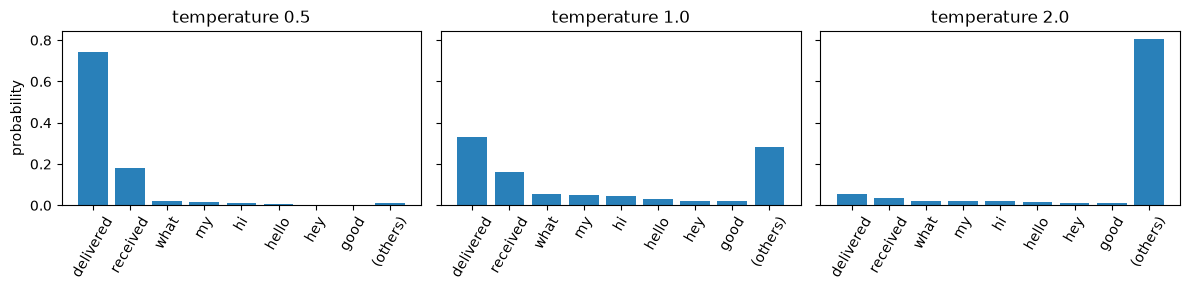

In [27]:
temps = [0.5, 1.0, 2.0]
table = pd.DataFrame({f"temperature {t}": probabilities(raw_scores, t)[top8] for t in temps},
                     index=[lm_words[i] for i in top8])
table.loc["(others)"] = [1 - probabilities(raw_scores, t)[top8].sum() for t in temps]
print(table.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, t in zip(axes, temps):
    ax.bar(table.index, table[f"temperature {t}"], color="#2980b9")
    ax.set_title(f"temperature {t}")
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("probability")
plt.tight_layout(); plt.show()

At temperature 0.5 the top word takes over; at 2.0 the probability leaks out
into the long tail of *(others)*, most of which are words that make no sense
after *my order has not*.

**Top-p** (also called *nucleus sampling*) keeps only the most likely words
whose probabilities add up to *p*, and never samples from the rest. It cuts
off that long tail while still allowing variety among sensible words:

In [28]:
def top_p_keep(probs, p_limit):
    order = np.argsort(-probs)
    cumulative = np.cumsum(probs[order])
    n_keep = int(np.searchsorted(cumulative, p_limit) + 1)   # the smallest set that reaches p_limit
    return [lm_words[i] for i in order[:n_keep]]

for t in temps:
    kept = top_p_keep(probabilities(raw_scores, t), 0.9)
    shown = ", ".join(kept[:6]) + (", ..." if len(kept) > 6 else "")
    print(f"temperature {t}: top-p 0.9 keeps {len(kept):>3} words   ({shown})")

p2 = probabilities(raw_scores, 2.0)
order = np.argsort(-p2)
removed = [lm_words[i] for i in order[len(top_p_keep(p2, 0.9)):] if i > 2]
print(f"\nat temperature 2.0 it still removes {len(removed)} words that had some probability left, such as:")
print("   " + ", ".join(removed[-10:]))

temperature 0.5: top-p 0.9 keeps   2 words   (delivered, received)
temperature 1.0: top-p 0.9 keeps  46 words   (delivered, received, what, my, hi, hello, ...)
temperature 2.0: top-p 0.9 keeps 416 words   (delivered, received, what, my, hi, hello, ...)

at temperature 2.0 it still removes 336 words that had some probability left, such as:
   wash, kayak, help, brightness, hold, clean, cooler, 65, bag, expedite


The same top-p setting keeps two words when the model is confident and lets
hundreds through when the probabilities are flat — but even then it removes the
far tail, the words that could only appear by accident. Now watch temperature
change actual writing — the model continues the prefix one sampled word at a
time until it produces `<end>` or runs out of room:

In [29]:
def write(prefix, temperature=1.0, max_words=14):
    words_out = tokenize(prefix)
    for _ in range(max_words):
        ids = torch.tensor([[lm_vocab.get(w, 1) for w in words_out]])
        with torch.no_grad():
            p = probabilities(writer(ids)[0, -1].numpy(), temperature)
        i = int(np.random.choice(len(p), p=p))                      # sample one word
        if i == 2:                                                  # <end>
            break
        words_out.append(lm_words[i])
    return " ".join(words_out)

for t in [0.5, 2.0]:
    np.random.seed(SEED)
    print(f"temperature {t}:")
    for _ in range(2):
        print(f"   {write(PREFIX, temperature=t)}")
    print()

temperature 0.5:
   my order has not delivered but there is the ridgeline 2p tent true season tent or more of
   my order has not delivered if refuse the package at delivery do still have to pay return shipping

temperature 2.0:
   my order has not site 43895 day 19 this on the emailed does four <unk> 54369 use before
   my order has not there please hi been below ship contacted you shows but sleeping several friday avery



Low temperature: on-topic, and the same few continuations every time. High
temperature: varied, and increasingly nonsense. Low temperature for factual
replies, higher for brainstorming, and a top-p cut-off to keep the accidental
tail out — that is most of what you need to know to set these knobs sensibly.
(A five-second model on 1,758 tickets writes like a five-second model; the
knobs behave exactly the same way on the real thing.)

---
## 8 — Where this leaves us

| Week | How a computer represents text | Limitation |
|---|---|---|
| 2 | **counts** — a document is which words it contains | no meaning, no order |
| 4 | **word vectors + reading in order** — meaning per word, a running memory across the text | reads one word at a time: slow, memory fades on long text, and it cannot look back at what it read |
| 5 | **attention + transformers** — every word looks at every other word at once | *next week* |

Three of the four parts of every modern language model are now in your hands:
the **embedding** that turns words into vectors, a **running state** that reads
them in order, and **choosing the next word** from a probability list. The
fourth — **attention**, the ability to look back at any earlier word instead of
relying on a fading memory — is where next week starts.